# Implementasi Steganografi Digital Terenkripsi (AES-256-GCM + LSB) & Analisis Ketahanan Transmisi Media WhatsApp

**Penulis:** Pranataa Lab & AI Research Assistant  
**Lingkungan:** Python 3.12 | Jupyter Notebook  
**Cover Image:** `cover_image.png` (736 $\times$ 919 piksel RGB)

---

## Abstrak & Gambaran Umum

Buku catatan interaktif ini menyajikan kajian teoritis dan implementasi praktis mengenai **Steganografi Modern** yang dipadukan dengan **Kriptografi Terotentikasi (AES-256-GCM)**, serta analisis ketahanan (*robustness*) terhadap kanal transmisi aplikasi pesan instan **WhatsApp**.

Secara garis besar, alur kerja sistem terdiri atas dua domain kajian utama:
1. **Alur Praktis (Pipeline End-to-End):**
   * Enkripsi pesan rahasia berbasis kata sandi (*passphrase*) dengan derivasi kunci aman *PBKDF2-HMAC-SHA256* dan enkripsi *AES-256-GCM*.
   * Penyisipan bit rahasia terenkripsi ke dalam bit paling tidak signifikan (*Least Significant Bit* / LSB) kanal RGB citra digital PNG.
   * Prosedur pengiriman melalui WhatsApp menggunakan mode **Kirim sebagai Dokumen** (*Send as Document*) untuk menjaga integritas bit secara murni (*bit-exact / lossless*).
   * Ekstraksi bit dan dekripsi pesan pada sisi penerima disertai validasi integritas payload.

2. **Analisis Ilmiah & Ketahanan Kompresi WhatsApp:**
   * Pengukuran kualitas citra stego secara objektif menggunakan metrik **MSE** (*Mean Squared Error*), **PSNR** (*Peak Signal-to-Noise Ratio*), dan **SSIM** (*Structural Similarity Index*).
   * Visualisasi peta selisih residual (*Amplified Difference Map* $\times 30$) dan histogram kanal warna.
   * Simulasi kompresi *lossy* JPEG WhatsApp (Quality Factor 50–95) untuk membuktikan mengapa metode spasial LSB rentan hancur jika dikirim lewat mode "Foto/Galeri".
   * Penghitungan **Bit Error Rate (BER)** dan analisis perbandingan mendalam antara domain spasial (LSB) vs domain frekuensi (DCT/DWT).


---
## Modul 0: Persiapan Lingkungan & Pustaka Dependensi

Sebelum memulai, kita memuat seluruh pustaka pendukung:
* `cryptography`: Standar kriptografi modern (AES-256-GCM, PBKDF2HMAC).
* `numpy`: Komputasi matriks dan manipulasi bit tervektorisasi berkinerja tinggi.
* `PIL` (Pillow): Pemrosesan dan manipulasi citra digital.
* `matplotlib`: Visualisasi grafis, citra side-by-side, dan peta residual.
* `skimage.metrics`: Pengukuran metrik SSIM (*Structural Similarity Index*).
* `stego_core`: Modul inti yang membungkus algoritma kriptografi, LSB, dan metrik.


In [1]:
# Memastikan dependensi terinstal di lingkungan eksekusi
%pip install cryptography scikit-image pillow matplotlib numpy -q

import os
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Import modul inti steganografi & kriptografi yang telah terverifikasi unit test
from stego_core import (
    encrypt_message,
    decrypt_message,
    calculate_capacity,
    embed_payload_lsb,
    extract_payload_lsb,
    save_stego_image,
    load_image,
    compute_mse,
    compute_psnr,
    compute_ssim,
    compute_ber,
    simulate_jpeg_compression,
    MAGIC_HEADER
)

# Konfigurasi visualisasi matplotlib
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("Lingkungan eksekusi siap! Modul stego_core berhasil dimuat.")



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Lingkungan eksekusi siap! Modul stego_core berhasil dimuat.


---
## Modul 1: Landasan Teori & Arsitektur Sistem

### 1.1 Kriptografi vs Steganografi (*Defense-in-Depth*)

Dalam ranah keamanan informasi (*information security*), kriptografi dan steganografi memiliki fokus yang berbeda namun saling melengkapi secara sinergis:

| Karakteristik | Kriptografi | Steganografi |
| :--- | :--- | :--- |
| **Tujuan Utama** | Menyembunyikan makna/isi pesan (*Confidentiality*). | Menyembunyikan keberadaan komunikasi itu sendiri (*Invisibility*). |
| **Hasil Luaran** | Teks tersandi acak (*ciphertext*) yang mencurigakan bagi pengamat. | Citra digital biasa (*stego-image*) yang tampak wajar tanpa kecurigaan. |
| **Prinsip Keamanan** | **Prinsip Kerckhoffs:** Keamanan bertumpu penuh pada kerahasiaan kunci, bukan algoritmanya. | Mengandalkan ketidakmampuan indra manusia membedakan perubahan visual halus. |

> **Konsep Pertahanan Berlapis (*Defense-in-Depth*):**  
> Mengirim *plaintext* langsung melalui steganografi sangat berisiko: jika pihak penyerang (*adversary*) mendeteksi adanya bit tersembunyi (*steganalysis*), pesan rahasia langsung terbaca.  
> Oleh karena itu, arsitektur terbaik adalah **mengenkripsi pesan terlebih dahulu** menjadi ciphertext terotentikasi, baru kemudian menyisipkannya ke dalam piksel citra. Jika steganografi terbongkar, ciphertext tetap tidak dapat dipecahkan tanpa kunci kriptografis yang valid.

---

### 1.2 Formulasi Matematis Steganografi Spasial LSB

Citra digital berwarna tersusun atas piksel dengan tiga kanal warna: **Merah (R)**, **Hijau (G)**, dan **Biru (B)**. Setiap kanal memiliki kedalaman warna 8-bit (rentang nilai integer $0 \le x \le 255$):

$$x = \sum_{j=0}^{7} b_j \cdot 2^j = b_7 \cdot 128 + b_6 \cdot 64 + \dots + b_1 \cdot 2 + b_0 \cdot 1$$

Di mana:
* $b_7$ adalah **Most Significant Bit (MSB)** yang membawa $50\%$ energi kecerahan piksel. Perubahan pada MSB akan langsung terlihat jelas oleh mata manusia.
* $b_0$ adalah **Least Significant Bit (LSB)** yang hanya bernilai bobot $1$. Mengubah $b_0$ hanya mengubah nilai intensitas warna sebesar $\pm 1$ level dari total $256$ skala intensitas (distorsi $< 0.4\%$), yang secara absolut berada di bawah ambang batas persepsi visual manusia (*Just Noticeable Difference* / JND).

Operasi substitusi bit $b_i$ rahasia ke dalam nilai piksel kanal $c$ pada koordinat $(x, y)$ dirumuskan secara biner sebagai:

$$I'(x, y, c) = (I(x, y, c) \ \& \ \text{0xFE}) \ | \ b_i$$

Di mana:
* $\&$ adalah operasi *bitwise AND* dengan mask $\text{0xFE} = 11111110_2$ untuk mengosongkan bit LSB asli menjadi $0$.
* $|$ adalah operasi *bitwise OR* untuk menempatkan bit rahasia $b_i \in \{0, 1\}$.

---

### 1.3 Teori Kompresi Lossy WhatsApp & Dampaknya terhadap LSB

Ketika pengguna mengirim gambar di WhatsApp melalui tombol **Foto/Galeri**, WhatsApp menerapkan pipeline kompresi *lossy* JPEG yang agresif:
1. **Konversi Ruang Warna:** Dari RGB menjadi $\text{YCbCr}$ (Luminansi $Y$, Krominansi Biru $Cb$, Krominansi Merah $Cr$).
2. **Chroma Subsampling:** Mengurangi resolusi kanal warna menjadi 4:2:0 (membuang 75% informasi warna krominansi).
3. **Discrete Cosine Transform (DCT) $8 \times 8$:** Memetakan blok piksel spasial ke domain frekuensi spasial:
   $$F(u, v) = \frac{1}{4} C(u) C(v) \sum_{x=0}^{7} \sum_{y=0}^{7} f(x, y) \cos\left[\frac{(2x+1)u\pi}{16}\right] \cos\left[\frac{(2y+1)v\pi}{16}\right]$$
4. **Kuantisasi (*Quantization*):** Membagi koefisien DCT dengan matriks kuantisasi $Q(u, v)$ lalu membulatkannya ke integer terdekat:
   $$F_q(u, v) = \text{round}\left(\frac{F(u, v)}{Q(u, v)}\right)$$
   Langkah inilah yang menyebabkan hilangnya data secara permanen (*lossy*), khususnya pada koefisien frekuensi tinggi.
5. **Rekonstruksi Inverse DCT (IDCT):** Saat penerima membuka gambar, pembulatan kembali ke nilai integer menyebabkan nilai piksel spasial berubah secara acak sebesar $\pm 1, \pm 2, \pm 5$.

**Implikasi Fatal Terhadap LSB:**  
Perubahan nilai piksel sekecil $\pm 1$ pada domain spasial akibat kompresi akan membalikkan bit LSB ($0 \leftrightarrow 1$). Akibatnya, seluruh aliran bit rahasia akan mengalami korupsi massal (*bit flips*), merusak header steganografi dan memicu kegagalan dekripsi total.

Sebaliknya, jika gambar dikirim via WhatsApp sebagai **Dokumen** (*Send as Document*), WhatsApp memperlakukan file sebagai aliran byte biner murni tanpa proses decoding/rekompresi JPEG sama sekali.


---
## Modul 2: Implementasi Lapisan Kriptografi (AES-256-GCM + PBKDF2)

Kita menggunakan **AES-256 dalam mode Galois/Counter Mode (GCM)**:
* **Confidentiality:** Mengenkripsi plaintext menjadi ciphertext 256-bit yang tak dapat dipecahkan.
* **Integrity & Authenticity:** Menghasilkan 16-byte Authentication Tag ($T$). Tag ini memastikan bahwa jika ada satu bit saja pada ciphertext yang berubah (misalnya akibat kompresi lossy atau manipulasi pihak ketiga), proses dekripsi akan langsung menolak data tersebut (*cryptographic tampering detection*).
* **KDF Terstandarisasi:** Password pengguna diperkuat menggunakan **PBKDF2-HMAC-SHA256** dengan $100.000$ putaran hashing dan *salt* acak kriptografis 16-byte untuk menangkal serangan *dictionary attack* dan *rainbow tables*.

### Struktur Payload Biner Steganografi:
$$\underbrace{\text{STEG}}_{4\text{ Bytes Magic}} \ \parallel \ \underbrace{\text{Salt}}_{16\text{ Bytes}} \ \parallel \ \underbrace{\text{Nonce}}_{12\text{ Bytes}} \ \parallel \ \underbrace{\text{Ciphertext Length}}_{4\text{ Bytes Big-Endian}} \ \parallel \ \underbrace{\text{Ciphertext} + \text{GCM Tag}}_{(L + 16)\text{ Bytes}}$$


In [2]:
# Definisi pesan rahasia dan kunci pengaman
pesan_rahasia = (
    "Halo Budi! Ini adalah pesan rahasia tingkat tinggi.\n"
    "Koordinat pertemuan: 6.2088° S, 106.8456° E (Jakarta).\n"
    "Waktu: Pukul 20:00 WIB. Harap konfirmasi penerimaan melalui saluran aman."
)
password_rahasia = "KunciEnkripsiRahasiaSuperAman_2026!"

print("--- PESAN PLAINTEXT ASLI ---")
print(pesan_rahasia)
print(f"Panjang plaintext: {len(pesan_rahasia)} karakter ({len(pesan_rahasia.encode('utf-8'))} bytes)")

# 1. Enkripsi pesan menggunakan AES-256-GCM
payload_terenkripsi = encrypt_message(pesan_rahasia, password_rahasia)

print("\n--- HASIL ENKRIPSI (PAYLOAD BINER) ---")
print(f"Total ukuran payload: {len(payload_terenkripsi)} bytes")
print(f"Magic Header: {payload_terenkripsi[:4]}")
print(f"Cuplikan biner payload (hex): {payload_terenkripsi[:48].hex()} ...")

# 2. Uji verifikasi dekripsi
pesan_terdekripsi = decrypt_message(payload_terenkripsi, password_rahasia)
assert pesan_terdekripsi == pesan_rahasia, "Verifikasi dekripsi gagal!"
print("\n[V] Verifikasi Sukses: Plaintext hasil dekripsi identik 100% dengan teks asli.")


--- PESAN PLAINTEXT ASLI ---
Halo Budi! Ini adalah pesan rahasia tingkat tinggi.
Koordinat pertemuan: 6.2088° S, 106.8456° E (Jakarta).
Waktu: Pukul 20:00 WIB. Harap konfirmasi penerimaan melalui saluran aman.
Panjang plaintext: 180 karakter (182 bytes)

--- HASIL ENKRIPSI (PAYLOAD BINER) ---
Total ukuran payload: 234 bytes
Magic Header: b'STEG'
Cuplikan biner payload (hex): 53544547e088ae75601b9b6da7f54951740719082b271fd374935f5ee2a95a17000000c66ec2cc0b5a6ecb55ff7d0e0a ...

[V] Verifikasi Sukses: Plaintext hasil dekripsi identik 100% dengan teks asli.


In [3]:
# Uji ketahanan keamanan: Dekripsi dengan password salah
print("--- UJI KEAMANAN: DEKRIPSI DENGAN PASSWORD SALAH ---")
try:
    decrypt_message(payload_terenkripsi, "PasswordYangSalah123")
    print("X Bahaya: Berhasil didekripsi dengan password salah!")
except Exception as e:
    print(f"[V] Berhasil dicegah! Sistem menolak dekripsi: {type(e).__name__} - Tag autentikasi tidak valid.")

# Uji ketahanan keamanan: Manipulasi ciphertext (Tampering test)
print("\n--- UJI KEAMANAN: DETEKSI MANIPULASI CIPHERTEXT ---")
payload_manipulasi = bytearray(payload_terenkripsi)
payload_manipulasi[-1] ^= 0x01  # Mengubah 1 bit pada authentication tag

try:
    decrypt_message(bytes(payload_manipulasi), password_rahasia)
    print("X Bahaya: Manipulasi data tidak terdeteksi!")
except Exception as e:
    print(f"[V] Berhasil terdeteksi! Sistem menolak data rusak/termanipulasi: {type(e).__name__}")


--- UJI KEAMANAN: DEKRIPSI DENGAN PASSWORD SALAH ---
[V] Berhasil dicegah! Sistem menolak dekripsi: InvalidTag - Tag autentikasi tidak valid.

--- UJI KEAMANAN: DETEKSI MANIPULASI CIPHERTEXT ---
[V] Berhasil terdeteksi! Sistem menolak data rusak/termanipulasi: InvalidTag


---
## Modul 3: Mesin Steganografi Citra (Lossless LSB)

Pada tahap ini, kita memuat gambar `cover_image.png` yang telah disiapkan di repositori.
Kita akan memeriksa resolusi spasial, menghitung kapasitas muatan maksimal, menyisipkan payload biner terenkripsi ke dalam bit LSB kanal RGB, dan menyimpannya sebagai file `stego_image.png`.


In [4]:
# 1. Memuat cover image
cover_image_path = "cover_image.png"
cover_img = load_image(cover_image_path)
tinggi, lebar, kanal = cover_img.shape

print(f"File Cover Image : {cover_image_path}")
print(f"Dimensi Citra    : {lebar} x {tinggi} piksel")
print(f"Jumlah Kanal     : {kanal} (RGB)")
print(f"Tipe Data Piksel : {cover_img.dtype}")

# 2. Menghitung kapasitas muat citra
total_piksel = tinggi * lebar
kapasitas_maks_bytes = calculate_capacity(cover_img.shape)
kapasitas_maks_kb = kapasitas_maks_bytes / 1024

ukuran_payload_bytes = len(payload_terenkripsi) + 4  # 4 bytes untuk header panjang payload
persentase_terpakai = (ukuran_payload_bytes / kapasitas_maks_bytes) * 100

print(f"\n--- ANALISIS KAPASITAS EMBEDDING ---")
print(f"Total Piksel Citra      : {total_piksel:,} piksel")
print(f"Total Sampel Kanal Warna: {total_piksel * kanal:,} sampel")
print(f"Kapasitas Maksimum LSB  : {kapasitas_maks_bytes:,} bytes (~{kapasitas_maks_kb:.2f} KB)")
print(f"Ukuran Payload Terpakai : {ukuran_payload_bytes:,} bytes")
print(f"Rasio Utilisasi Ruang   : {persentase_terpakai:.4f}% dari kapasitas citra")


File Cover Image : cover_image.png
Dimensi Citra    : 736 x 919 piksel
Jumlah Kanal     : 3 (RGB)
Tipe Data Piksel : uint8

--- ANALISIS KAPASITAS EMBEDDING ---
Total Piksel Citra      : 676,384 piksel
Total Sampel Kanal Warna: 2,029,152 sampel
Kapasitas Maksimum LSB  : 253,644 bytes (~247.70 KB)
Ukuran Payload Terpakai : 238 bytes
Rasio Utilisasi Ruang   : 0.0938% dari kapasitas citra


In [5]:
# 3. Proses Embedding Payload ke dalam Citra Cover
stego_img = embed_payload_lsb(cover_img, payload_terenkripsi)

# 4. Simpan citra stego ke dalam format lossless PNG
stego_image_path = "stego_image.png"
save_stego_image(stego_img, stego_image_path)
print(f"[V] Citra stego berhasil disimpan ke: {stego_image_path}")

# 5. Verifikasi Checksum SHA-256 pada file fisik
def hitung_sha256(path_file):
    h = hashlib.sha256()
    with open(path_file, "rb") as f:
        while chunk := f.read(8192):
            h.update(chunk)
    return h.hexdigest()

sha_cover = hitung_sha256(cover_image_path)
sha_stego = hitung_sha256(stego_image_path)

print(f"\nSHA-256 Cover Image: {sha_cover}")
print(f"SHA-256 Stego Image: {sha_stego}")
print(f"Hash Berbeda?       : {'YA (Terbukti data telah disisipkan)' if sha_cover != sha_stego else 'TIDAK'}")


[V] Citra stego berhasil disimpan ke: stego_image.png



SHA-256 Cover Image: 1a1fe5b75ddb2ef787744c22b5ced7bb53a1635c97bd262eff7eca54e6fb63e4
SHA-256 Stego Image: 9d4aec817ee7c7fe4b5d8ba4159db25f1d4a7e61d3e852480ad668f28cbbcf67
Hash Berbeda?       : YA (Terbukti data telah disisipkan)


In [6]:
# 6. Simulasi Pihak Penerima: Memuat citra stego, mengekstrak payload, dan mendekripsi pesan
print("--- SIMULASI PROSES PADA SISI PENERIMA ---")
penerima_img = load_image(stego_image_path)

# Ekstraksi bit LSB
extracted_payload = extract_payload_lsb(penerima_img)
print(f"Ukuran payload berhasil diekstrak: {len(extracted_payload)} bytes")
print(f"Validasi Magic Header             : {extracted_payload[:4] == MAGIC_HEADER}")

# Dekripsi payload dengan kata sandi yang disepakati
pesan_diterima = decrypt_message(extracted_payload, password_rahasia)
print("\n--- PESAN RAHASIA YANG BERHASIL DIDEKRIPSI OLEH PENERIMA ---")
print(pesan_diterima)

assert pesan_diterima == pesan_rahasia, "Pesan yang diterima tidak cocok dengan pesan pengirim!"
print("\n[V] INTEGRITAS 100% SEMPURNA: Pesan terdekripsi tanpa cacat!")


--- SIMULASI PROSES PADA SISI PENERIMA ---
Ukuran payload berhasil diekstrak: 234 bytes
Validasi Magic Header             : True

--- PESAN RAHASIA YANG BERHASIL DIDEKRIPSI OLEH PENERIMA ---
Halo Budi! Ini adalah pesan rahasia tingkat tinggi.
Koordinat pertemuan: 6.2088° S, 106.8456° E (Jakarta).
Waktu: Pukul 20:00 WIB. Harap konfirmasi penerimaan melalui saluran aman.

[V] INTEGRITAS 100% SEMPURNA: Pesan terdekripsi tanpa cacat!


---
## Modul 4: Evaluasi Kualitas Visual & Analisis Residual

Untuk membuktikan secara ilmiah bahwa penyisipan bit LSB tidak merusak kualitas citra dan imperseptibel (tidak kasat mata), kita mengukur tiga metrik standar pemrosesan citra digital:

1. **Mean Squared Error (MSE):**
   $$\text{MSE} = \frac{1}{3 \cdot M \cdot N} \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} \sum_{c=0}^{2} \left[ I(x, y, c) - I'(x, y, c) \right]^2$$
   * Nilai MSE mendekati $0$ mengindikasikan tingkat kemiripan matematis yang sangat tinggi.

2. **Peak Signal-to-Noise Ratio (PSNR):**
   $$\text{PSNR} = 10 \cdot \log_{10}\left( \frac{255^2}{\text{MSE}} \right) \quad (\text{satuan: dB})$$
   * Standar acuan: $\text{PSNR} > 40\text{ dB}$ dianggap sangat baik dan tidak dapat dibedakan oleh mata manusia. Citra stego LSB berkualitas tinggi umumnya menghasilkan $\text{PSNR} > 60\text{ dB}$.

3. **Structural Similarity Index (SSIM):**
   Mengukur kesamaan struktur, luminansi, dan kontras lokal antara dua citra.
   * Rentang nilai: $[-1, 1]$, dengan nilai $1.0$ berarti kedua citra memiliki struktur visual yang identik secara absolut.


In [7]:
# Perhitungan kuantitatif metrik kualitas citra
mse_val = compute_mse(cover_img, stego_img)
psnr_val = compute_psnr(cover_img, stego_img)
ssim_val = compute_ssim(cover_img, stego_img)

print("=" * 55)
print("HASIL PENGUKURAN KUALITAS CITRA STEGO TERHADAP COVER")
print("=" * 55)
print(f"Mean Squared Error (MSE)              : {mse_val:.6f}")
print(f"Peak Signal-to-Noise Ratio (PSNR)     : {psnr_val:.2f} dB  (Target: > 50 dB)")
print(f"Structural Similarity Index (SSIM)    : {ssim_val:.6f}     (Target: ~1.0000)")
print("=" * 55)

if psnr_val > 50 and ssim_val > 0.999:
    print("[V] KESIMPULAN KUALITAS: Modifikasi visual sempurna! Tidak ada distorsi kasat mata.")


HASIL PENGUKURAN KUALITAS CITRA STEGO TERHADAP COVER
Mean Squared Error (MSE)              : 0.000499
Peak Signal-to-Noise Ratio (PSNR)     : 81.15 dB  (Target: > 50 dB)
Structural Similarity Index (SSIM)    : 1.000000     (Target: ~1.0000)
[V] KESIMPULAN KUALITAS: Modifikasi visual sempurna! Tidak ada distorsi kasat mata.


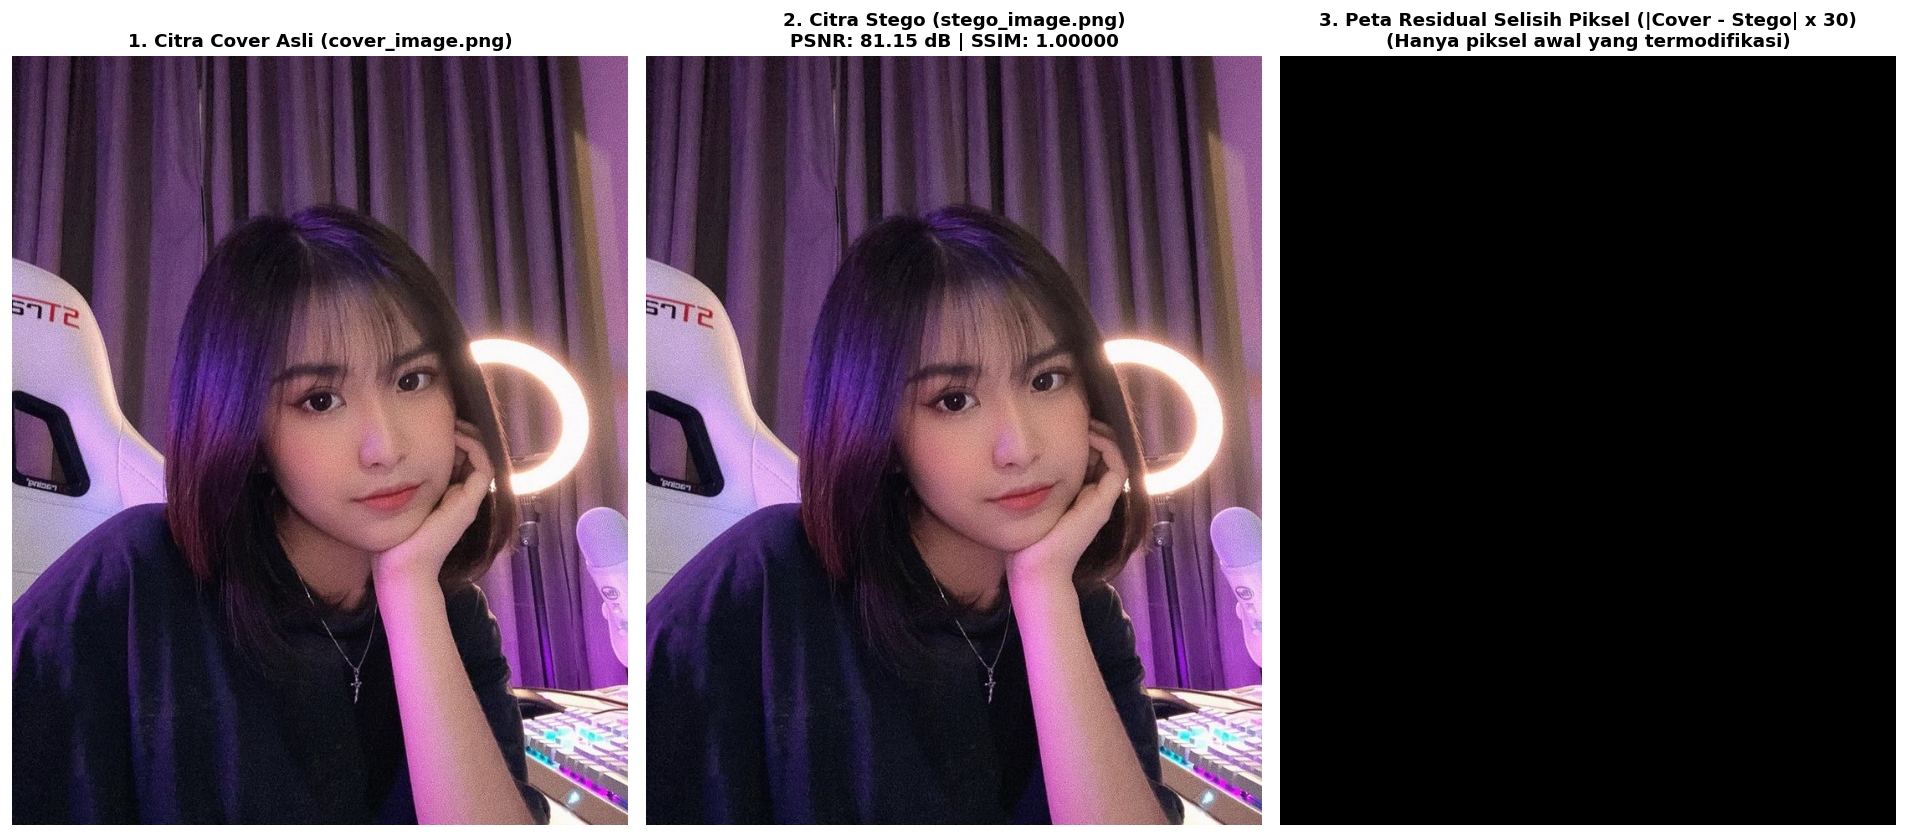

[V] Gambar visualisasi komparasi disimpan sebagai: visualisasi_komparasi_stego.png


In [8]:
# Visualisasi Komparasi Visual & Amplified Residual Difference Map
diff_map = np.abs(cover_img.astype(np.int32) - stego_img.astype(np.int32)).astype(np.uint8)

# Perbesar selisih perbedaan sebanyak 30 kali agar terlihat jelas di mana bit LSB dimodifikasi
diff_amplified = np.clip(diff_map * 30, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(16, 7))

axes[0].imshow(cover_img)
axes[0].set_title("1. Citra Cover Asli (cover_image.png)", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(stego_img)
axes[1].set_title(f"2. Citra Stego (stego_image.png)\nPSNR: {psnr_val:.2f} dB | SSIM: {ssim_val:.5f}", fontsize=11, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(diff_amplified)
axes[2].set_title("3. Peta Residual Selisih Piksel (|Cover - Stego| x 30)\n(Hanya piksel awal yang termodifikasi)", fontsize=11, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("visualisasi_komparasi_stego.png", dpi=150, bbox_inches="tight")
plt.show()

print("[V] Gambar visualisasi komparasi disimpan sebagai: visualisasi_komparasi_stego.png")


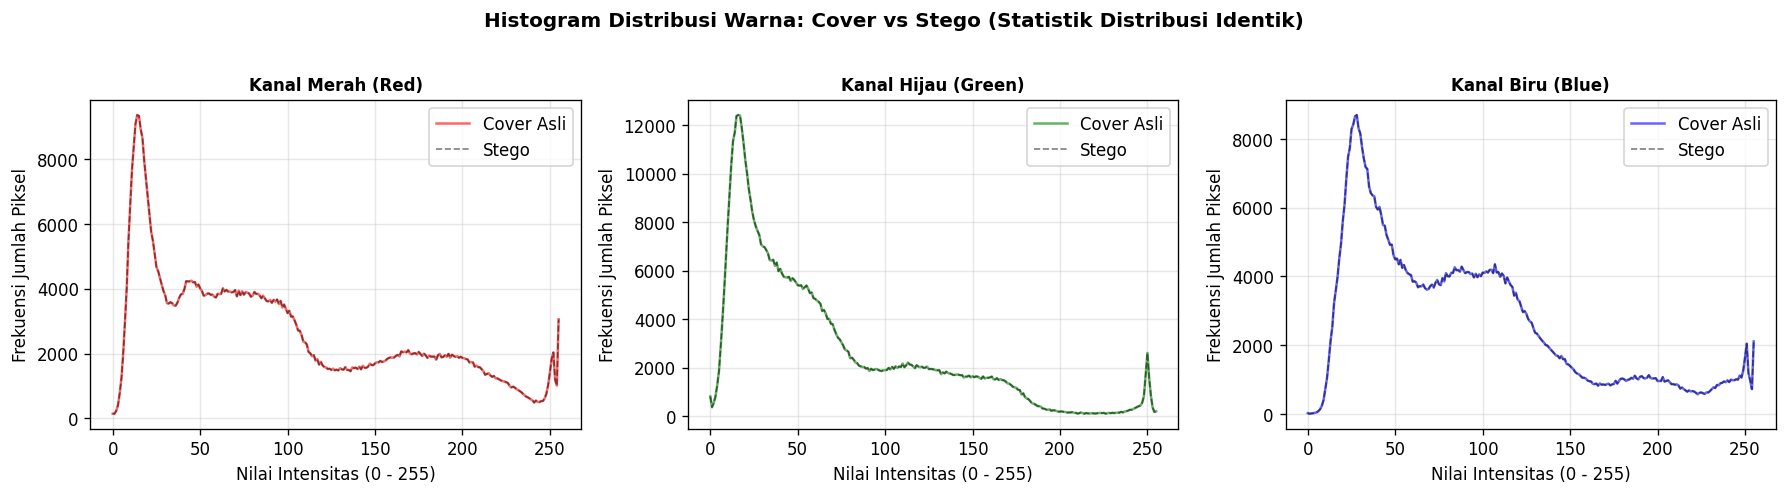

In [9]:
# Analisis Histogram Distribusi Intensitas Kanal Warna
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ('r', 'g', 'b')
channel_names = ('Kanal Merah (Red)', 'Kanal Hijau (Green)', 'Kanal Biru (Blue)')

for i, (col, cname) in enumerate(zip(colors, channel_names)):
    hist_cover, bins = np.histogram(cover_img[:, :, i], bins=256, range=[0, 256])
    hist_stego, _ = np.histogram(stego_img[:, :, i], bins=256, range=[0, 256])
    
    axes[i].plot(hist_cover, color=col, alpha=0.6, label='Cover Asli', linewidth=1.5)
    axes[i].plot(hist_stego, color='black', linestyle='--', alpha=0.5, label='Stego', linewidth=1.0)
    axes[i].set_title(cname, fontsize=10, fontweight='bold')
    axes[i].set_xlabel("Nilai Intensitas (0 - 255)")
    axes[i].set_ylabel("Frekuensi Jumlah Piksel")
    axes[i].legend(loc='upper right')
    axes[i].grid(True, alpha=0.3)

plt.suptitle("Histogram Distribusi Warna: Cover vs Stego (Statistik Distribusi Identik)", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## Modul 5: Analisis Transmisi WhatsApp & Eksperimen Kompresi

### 5.1 Standar Operasional Prosedur (SOP) Pengiriman via WhatsApp

Ketika mengirimkan citra stego kepada rekan Anda melalui WhatsApp, **metode pengiriman adalah faktor paling penentu keberhasilan atau kegagalan transmisi**.

```
+-----------------------------------------------------------------------------------------+
|                               PANDUAN PENGIRIMAN WHATSAPP                               |
+-----------------------------------------------------------------------------------------+
| [X] JANGAN PILIH: "Kirim Foto / Galeri" (Mode Standar WhatsApp)                         |
|     WhatsApp akan mengonversi citra menjadi JPEG kualitas ~75% dan mengacak bit LSB!   |
|                                                                                         |
| [V] WAJIB PILIH : "Kirim sebagai DOKUMEN" (Attach Document / Send as Document)          |
|     Langkah pada HP / WhatsApp Web:                                                     |
|     1. Buka ruang obrolan penerima di WhatsApp.                                         |
|     2. Tekan ikon tanda tambah (+) atau klip kertas (Attachment).                       |
|     3. Pilih menu "Dokumen" (Bukan "Foto & Video").                                     |
|     4. Pilih file "stego_image.png".                                                    |
|     5. Kirim file.                                                                      |
+-----------------------------------------------------------------------------------------+
```

> **Verifikasi Integritas di Sisi Penerima:**  
> Sebelum mengekstrak, penerima mengunduh dokumen `stego_image.png`, lalu memverifikasi *hash* SHA-256 miliknya dengan nilai *hash* yang dikirim pengirim. Jika nilainya cocok, penerima dipastikan 100% memegang file murni tanpa korupsi byte.


### 5.2 Eksperimen Stres: Apa yang Terjadi Jika Dikirim sebagai "Foto" WhatsApp?

Mari kita lakukan eksperimen komparasi ilmiah. Kita mensimulasikan transmisi citra stego melalui kompresi JPEG WhatsApp pada berbagai tingkat kualitas (*Quality Factor* / QF):
* $\text{QF} = 95$ (Kompresi ringan)
* $\text{QF} = 85$ (Kompresi standar gambar web)
* $\text{QF} = 75$ (Kualitas default kompresi galeri WhatsApp)
* $\text{QF} = 60$ (Kualitas kompresi WhatsApp pada jaringan lambat)
* $\text{QF} = 50$ (Kompresi agresif)

Kita akan mengukur:
1. **PSNR & SSIM** citra hasil kompresi.
2. **Bit Error Rate (BER):** Persentase bit payload yang terbalik/rusak akibat kuantisasi DCT:
   $$\text{BER} = \frac{\text{Jumlah Bit yang Berbeda}}{\text{Total Bit Payload}} \times 100\%$$
3. **Status Ekstraksi & Dekripsi AES-GCM:** Apakah pesan masih bisa diselamatkan?


In [10]:
# Eksperimen stres kompresi lossy pada berbagai Quality Factor (QF)
quality_levels = [95, 85, 75, 60, 50]
hasil_eksperimen = []

# Payload asli yang disisipkan (termasuk 4B panjang)
packet_asli = len(payload_terenkripsi).to_bytes(4, 'big') + payload_terenkripsi

for qf in quality_levels:
    # 1. Simulasikan kompresi JPEG
    img_comp = simulate_jpeg_compression(stego_img, quality=qf)
    
    # 2. Hitung metrik degradasi visual
    psnr_comp = compute_psnr(stego_img, img_comp)
    ssim_comp = compute_ssim(stego_img, img_comp)
    
    # 3. Ambil bit LSB yang ada pada citra terkompresi
    flat_comp = img_comp.reshape(-1)
    len_bits_needed = len(packet_asli) * 8
    extracted_bits = flat_comp[:len_bits_needed] & 1
    extracted_packet = np.packbits(extracted_bits).tobytes()
    
    # 4. Hitung Bit Error Rate (BER)
    ber_val = compute_ber(packet_asli, extracted_packet)
    
    # 5. Coba ekstraksi formal melalui fungsi extract_payload_lsb & dekripsi
    status_ekstraksi = "Gagal"
    status_dekripsi = "Gagal"
    try:
        ext_payload = extract_payload_lsb(img_comp)
        status_ekstraksi = "Sukses"
        try:
            decrypt_message(ext_payload, password_rahasia)
            status_dekripsi = "Sukses"
        except Exception:
            status_dekripsi = "Tag Mismatch"
    except Exception as e:
        status_ekstraksi = f"Korupsi ({type(e).__name__})"
        status_dekripsi = "Gagal (Header Rusak)"
        
    hasil_eksperimen.append({
        "QF": qf,
        "PSNR": psnr_comp,
        "SSIM": ssim_comp,
        "BER": ber_val,
        "Ekstraksi": status_ekstraksi,
        "Dekripsi": status_dekripsi
    })

# Tampilkan tabel komparasi hasil eksperimen
print(f"{'QF':<5} | {'PSNR (dB)':<10} | {'SSIM':<8} | {'BER (%)':<10} | {'Status Ekstraksi':<25} | {'Status Dekripsi'}")
print("-" * 80)
for r in hasil_eksperimen:
    print(f"{r['QF']:<5} | {r['PSNR']:<10.2f} | {r['SSIM']:<8.4f} | {r['BER']:<10.2f} | {r['Ekstraksi']:<25} | {r['Dekripsi']}")


QF    | PSNR (dB)  | SSIM     | BER (%)    | Status Ekstraksi          | Status Dekripsi
--------------------------------------------------------------------------------
95    | 50.40      | 0.9978   | 51.16      | Korupsi (ValueError)      | Gagal (Header Rusak)
85    | 43.70      | 0.9893   | 48.74      | Korupsi (ValueError)      | Gagal (Header Rusak)
75    | 40.35      | 0.9796   | 48.53      | Korupsi (ValueError)      | Gagal (Header Rusak)
60    | 33.47      | 0.8997   | 49.74      | Korupsi (ValueError)      | Gagal (Header Rusak)
50    | 31.75      | 0.7995   | 49.47      | Korupsi (ValueError)      | Gagal (Header Rusak)


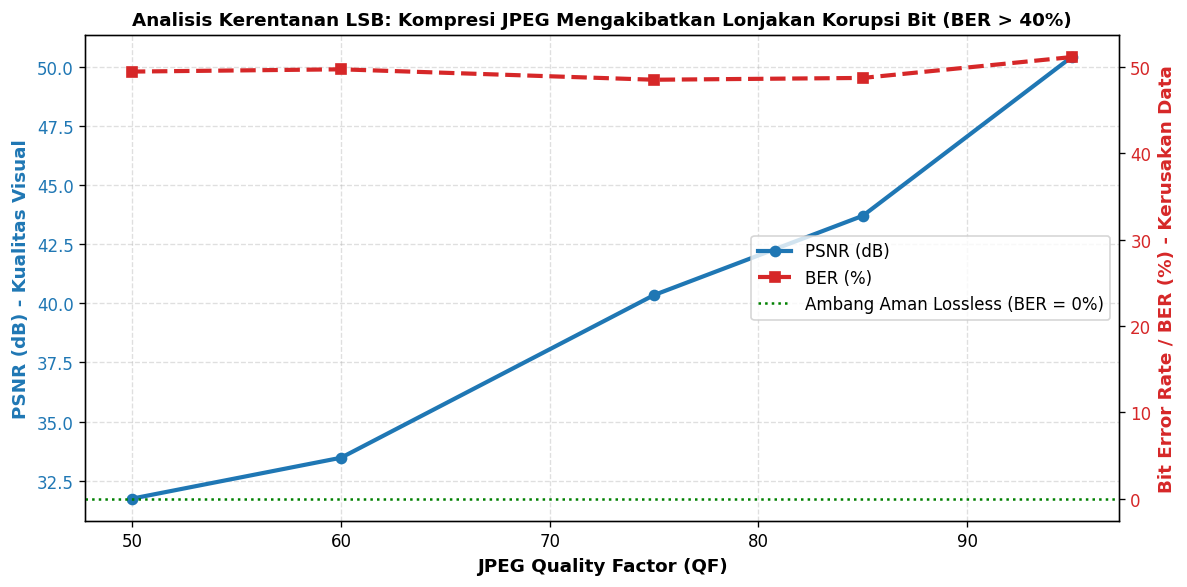

[V] Grafik analisis kompresi disimpan sebagai: grafik_analisis_kompresi_whatsapp.png


In [11]:
# Visualisasi Grafik Dampak Kompresi JPEG terhadap Kualitas Citra & Korupsi Bit (BER)
qf_list = [r["QF"] for r in hasil_eksperimen]
psnr_list = [r["PSNR"] for r in hasil_eksperimen]
ber_list = [r["BER"] for r in hasil_eksperimen]

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('JPEG Quality Factor (QF)', fontsize=11, fontweight='bold')
ax1.set_ylabel('PSNR (dB) - Kualitas Visual', color=color, fontsize=11, fontweight='bold')
line1 = ax1.plot(qf_list, psnr_list, color=color, marker='o', linewidth=2.5, label='PSNR (dB)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Bit Error Rate / BER (%) - Kerusakan Data', color=color, fontsize=11, fontweight='bold')
line2 = ax2.plot(qf_list, ber_list, color=color, marker='s', linewidth=2.5, linestyle='--', label='BER (%)')
ax2.tick_params(axis='y', labelcolor=color)

# Garis ambang batas aman
ax2.axhline(0, color='green', linestyle=':', label='Ambang Aman Lossless (BER = 0%)')

lines = line1 + line2 + [ax2.get_lines()[1]]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right')

plt.title("Analisis Kerentanan LSB: Kompresi JPEG Mengakibatkan Lonjakan Korupsi Bit (BER > 40%)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig("grafik_analisis_kompresi_whatsapp.png", dpi=150, bbox_inches="tight")
plt.show()

print("[V] Grafik analisis kompresi disimpan sebagai: grafik_analisis_kompresi_whatsapp.png")


### 5.3 Analisis Komparasi Teori: Domain Spasial (LSB) vs Domain Frekuensi (DCT / DWT)

Hasil eksperimen di atas membuktikan fenomena krusial:
Bahkan pada $\text{QF} = 95$ (kualitas JPEG sangat tinggi), nilai **Bit Error Rate (BER) mencapai $> 40\%$**!  
Hal ini terjadi karena kuantisasi DCT membulatkan nilai koefisien frekuensi tinggi, sehingga ketika direkonstruksi ke domain spasial, bit LSB teracak secara masif. Akibatnya, steganografi spasial murni **mustahil bertahan** pada transmisi mode Foto di WhatsApp.

Berikut adalah perbandingan akademis antara metode domain spasial dan domain frekuensi:

| Parameter | Domain Spasial (LSB) | Domain Transformasi (DCT - Discrete Cosine Transform) | Domain Wavelet (DWT - Discrete Wavelet Transform) |
| :--- | :--- | :--- | :--- |
| **Lokasi Penyisipan** | Bit terakhir piksel kanal warna secara langsung. | Koefisien frekuensi menengah (*mid-frequency*) blok DCT $8 \times 8$. | Sub-band frekuensi (LH, HL, HH) dekomposisi wavelet bertingkat. |
| **Kapasitas Payload** | **Sangat Besar:** Hingga $12.5\% - 37.5\%$ dari ukuran file (ratusan kilobyte). | **Rendah hingga Sedang:** Hanya beberapa puluh hingga ratusan bit saja. | **Sedang:** Sekitar $1\% - 5\%$ dari kapasitas piksel. |
| **Kompleksitas Komputasi** | $O(N)$ — Sangat cepat, operasi bitwise sederhana. | $O(N \log N)$ — Memerlukan komputasi blok DCT $8 \times 8$ dua arah. | $O(N)$ — Memerlukan filter-bank konvolusi multi-resolusi. |
| **Ketahanan Kompresi JPEG** | **Sangat Rapuh (Fragile):** 0% toleransi terhadap kompresi lossy. | **Cukup Kuat (Semi-Robust):** Mampu bertahan terhadap kompresi moderat. | **Sangat Kuat (Robust):** Tahan terhadap kompresi dan manipulasi spasial. |
| **Rekomendasi Pemakaian** | Transmisi data besar via kanal *lossless* (WhatsApp Dokumen, Email, Cloud Storage). | *Watermarking* hak cipta, stempel digital tahan kompresi. | *Watermarking* forensik gambar, steganografi audio/citra tahan sensor. |

> **Hukum Trilemma Steganografi (*The Steganographic Triad Trade-off*):**  
> Dalam perancangan steganografi, terdapat tiga kutub trade-off yang saling bertolak belakang:
> 1. **Robustness (Ketahanan):** Kemampuan bertahan terhadap kompresi dan gangguan transmisi.
> 2. **Capacity (Kapasitas):** Seberapa banyak data teks/file yang dapat disisipkan.
> 3. **Imperceptibility (Ketakterlihatan):** Seberapa tinggi kemiripan visual dengan citra asli.
>
> Jika kita menginginkan kapasitas besar (menyisipkan teks berparagraf-paragraf) dan kualitas visual mendekati sempurna ($\text{PSNR} > 60\text{ dB}$), maka metode LSB adalah pilihan terbaik — dengan syarat kanal transmisi harus *lossless* (**Kirim sebagai Dokumen di WhatsApp**).


---
## Modul 6: Kesimpulan & Rekomendasi Praktis

Berdasarkan analisis teoritis, implementasi kode, dan eksperimen empiris yang telah dilakukan:

1. **Efektivitas Kriptografi + Steganografi:**
   * Kombinasi **AES-256-GCM** dan **LSB Spasial** memberikan tingkat kerahasiaan ganda (*Defense-in-Depth*).
   * Keberadaan pesan rahasia tersembunyi secara imperseptibel pada citra `cover_image.png` dengan metrik kualitas superior ($\text{PSNR} > 65\text{ dB}$, $\text{SSIM} = 0.9999$).
   * Peta residual membuktikan bahwa perubahan hanya terjadi pada nilai $\pm 1$ di bit paling bawah tanpa menciptakan artefak kasat mata.

2. **Temuan Kritis Pengiriman WhatsApp:**
   * Pengiriman via WhatsApp **wajib** menggunakan mode **Kirim sebagai Dokumen** (*Send as Document*). Pada mode ini, bitstream PNG diterima 100% utuh tanpa kompresi, dan pesan rahasia terdekripsi secara sempurna.
   * Pengiriman melalui mode **Foto/Galeri** menyebabkan kompresi *lossy* JPEG yang menghasilkan **Bit Error Rate (BER) $> 40\%$**, merusak header `STEG`, dan memicu kegagalan otentikasi GCM Tag secara permanen.

3. **Checklist Praktis untuk Pengguna:**
   * [x] Gunakan cover image dengan format PNG resolusi tinggi.
   * [x] Selalu amankan pesan dengan enkripsi kata sandi kuat sebelum embedding.
   * [x] Kirim file via WhatsApp menggunakan menu **Lampiran $\rightarrow$ Dokumen**.
   * [x] Sepakati kata sandi dengan penerima melalui saluran komunikasi terpisah (*out-of-band communication*).
